# Bài 5: Cây quyết định và Rừng ngẫu nhiên
**Học máy ứng dụng — Trường Đại học Văn Lang, Khoa Công nghệ Thông tin**

Notebook giải toàn bộ `Lab05_CayQuyetDinh_RungNgauNhien.pdf` của ThS. Nguyễn Thái Anh.
Dữ liệu mô phỏng dùng để học thuật toán, gồm:

- `khach_vay.csv`: 600 hồ sơ, bốn đặc trưng và nhãn `tra_dung_han` (1: đúng hạn, 0: trễ hạn).
- `gia_nha.csv`: 60 căn hộ, dùng lại bài toán dự đoán giá nhà của Lab1.

| Phần | Nội dung | Tương ứng trong đề |
|---|---|---|
| A | 7 bước thực hành | Mục 2–8, `f1` … `f7` |
| B | 6 bài tập có lời giải và nhận xét | Mục 9 |

**Cách dùng:** giải nén `Lab05_data.zip` để có thư mục `data/` cạnh notebook, rồi chạy từ trên xuống
(`Kernel → Restart & Run All`). Cũng có thể đặt hai CSV trực tiếp cạnh notebook. Nếu mở Jupyter từ
gốc repo, mã tự tìm thư mục Lab5. Mọi hình được hiển thị trong notebook và lưu thêm vào `images/`.

**Thư viện:** `pip install numpy pandas matplotlib scikit-learn jupyter`.
Mã in phiên bản thư viện ở đầu để đối chiếu khi kết quả khác nhẹ do phiên bản.

## 0. Chuẩn bị môi trường

Giữ cùng cách chia dữ liệu với đề: phân loại dùng 450 khách học và 150 khách kiểm tra,
`random_state=17`, `stratify=y`; mô hình cây/rừng dùng `random_state=0`.
Hồi quy dùng 80% học, 20% kiểm tra, `random_state=42` như Lab1.

Các tham số được chọn bằng **kiểm định chéo 5 phần trên tập học**; điểm kiểm tra dùng để báo cáo.
Các thí nghiệm cùng dùng lại một tập kiểm tra nhằm so sánh theo đề, vì vậy không coi đó là đánh giá
độc lập cho một mô hình triển khai đã qua nhiều vòng lựa chọn.

In [1]:
from pathlib import Path
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

THU_MUC_LAB = (Path('05.DecisionTree_RandomForest')
               if Path('05.DecisionTree_RandomForest').is_dir() else Path('.'))


def tim_tep(ten_tep):
    for duong_dan in (THU_MUC_LAB / 'data' / ten_tep, THU_MUC_LAB / ten_tep):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(
        f'Không tìm thấy {ten_tep}. Hãy giải nén Lab05_data.zip vào thư mục Lab5 '
        'để có data/khach_vay.csv và data/gia_nha.csv.'
    )


THU_MUC_ANH = THU_MUC_LAB / 'images'
THU_MUC_ANH.mkdir(exist_ok=True)


def luu_hinh(ten_tep):
    plt.savefig(THU_MUC_ANH / ten_tep, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


plt.rcParams.update({'figure.figsize': (8, 5), 'figure.dpi': 110,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.family': 'DejaVu Sans'})
MAU_0, MAU_1, MAU_XANH = '#c53030', '#1a365d', '#2f855a'
print('Python:', platform.python_version())
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
print('matplotlib:', plt.matplotlib.__version__, '| scikit-learn:', sklearn.__version__)
print('Thư mục dữ liệu:', tim_tep('khach_vay.csv').parent)

Python: 3.11.9
NumPy: 1.26.4 | pandas: 2.3.3
matplotlib: 3.10.8 | scikit-learn: 1.8.0
Thư mục dữ liệu: data


---
# Phần A — Bài thực hành

## Bước 1 — Tự tính Gini và chọn câu hỏi *(Mục 2, `f1_gini.py`)*

Với tỷ lệ nhãn 1 là $p$, độ lẫn lộn của nút là $G=1-p^2-(1-p)^2$.
Nút thuần có $G=0$; hai lớp ngang nhau có $G=0.5$.

Sau một phép chia, $G_{chia}=\frac{n_T}{n}G_T+\frac{n_P}{n}G_P$.
Ta chọn câu hỏi làm $\Delta G=G_{gốc}-G_{chia}$ lớn nhất. Trọng số kích thước nhánh rất quan trọng:
một nhánh nhỏ thuần khiết không thể tự quyết định chất lượng cả phép chia.

In [2]:
nho = pd.DataFrame({
    'thu_nhap': [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    'co_viec_on_dinh': [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    'tra_dung_han': [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})


def gini(nhan):
    """Gini cho nhãn nhị phân 0/1; nút rỗng đóng góp bằng 0."""
    nhan = np.asarray(nhan)
    if len(nhan) == 0:
        return 0.0
    p = nhan.mean()
    return 1 - p**2 - (1 - p)**2


def gini_sau_chia(nhan, di_trai):
    nhan, di_trai = np.asarray(nhan), np.asarray(di_trai, dtype=bool)
    return (di_trai.mean() * gini(nhan[di_trai])
            + (~di_trai).mean() * gini(nhan[~di_trai]))


y_nho = nho['tra_dung_han'].to_numpy()
g_goc = gini(y_nho)
muc = np.unique(nho['thu_nhap'])
bang_gini = []
for nguong in (muc[:-1] + muc[1:]) / 2:
    g_chia = gini_sau_chia(y_nho, nho['thu_nhap'] <= nguong)
    bang_gini.append({'nguong': nguong, 'gini_sau_chia': g_chia, 'gini_giam': g_goc - g_chia})
bang_gini = pd.DataFrame(bang_gini)
display(nho)
print(f'Gini nút gốc: {g_goc:.4f}')
display(bang_gini.round(4))
g_viec = gini_sau_chia(y_nho, nho['co_viec_on_dinh'] == 0)
print(f'Câu hỏi việc làm: Gini sau chia = {g_viec:.4f}; giảm = {g_goc - g_viec:.4f}')
cay_mot_tang = DecisionTreeClassifier(max_depth=1, random_state=0).fit(
    nho[['thu_nhap', 'co_viec_on_dinh']], y_nho)
print(export_text(cay_mot_tang, feature_names=['thu_nhap', 'co_viec_on_dinh'], show_weights=True))
assert np.isclose(g_goc, 0.48)
assert np.isclose(cay_mot_tang.tree_.threshold[0], 12.0)

,thu_nhap,co_viec_on_dinh,tra_dung_han
0,6,0,0
1,8,0,1
2,9,0,0
3,11,1,0
4,13,1,1
5,15,1,1
6,18,1,0
7,20,1,1
8,25,1,1
9,30,1,1


Gini nút gốc: 0.4800


,nguong,gini_sau_chia,gini_giam
0,7.0,0.4000,0.0800
1,8.5,0.4750,0.0050
2,10.0,0.4190,0.0610
3,12.0,0.3167,0.1633
4,14.0,0.4000,0.0800
5,16.5,0.4500,0.0300
6,19.0,0.3429,0.1371
7,22.5,0.4000,0.0800
8,27.5,0.4444,0.0356


Câu hỏi việc làm: Gini sau chia = 0.4190; giảm = 0.0610
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



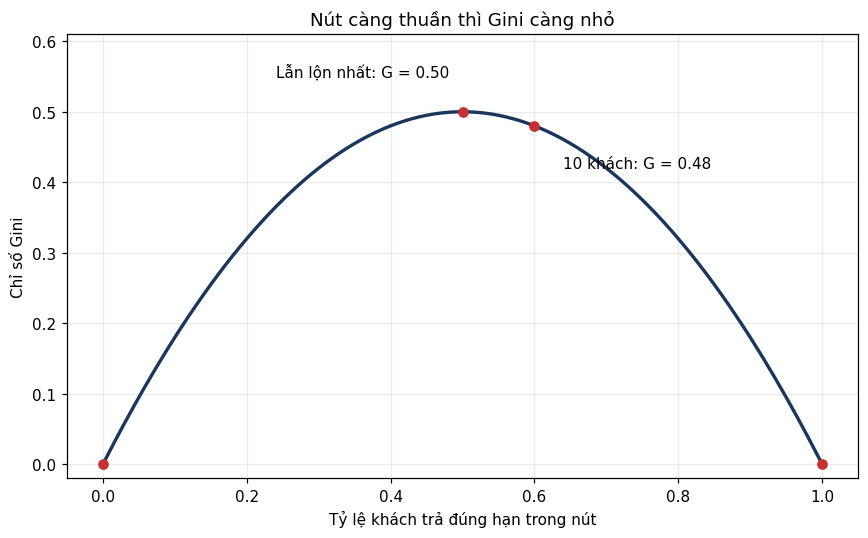

In [3]:
p = np.linspace(0, 1, 201)
plt.figure()
plt.plot(p, 1 - p**2 - (1-p)**2, color=MAU_1, linewidth=2.2)
plt.scatter([0, 0.5, 0.6, 1], [0, 0.5, 0.48, 0], color=MAU_0, zorder=3)
plt.annotate('Lẫn lộn nhất: G = 0.50', (0.5, 0.5), xytext=(0.24, 0.55))
plt.annotate('10 khách: G = 0.48', (0.6, 0.48), xytext=(0.64, 0.42))
plt.xlabel('Tỷ lệ khách trả đúng hạn trong nút')
plt.ylabel('Chỉ số Gini')
plt.ylim(-0.02, 0.61)
plt.title('Nút càng thuần thì Gini càng nhỏ')
plt.tight_layout()
luu_hinh('hinh1_chi_so_gini.png')

**Nhận xét:** 6 khách đúng hạn, 4 khách trễ hạn cho Gini 0.48. Ngưỡng thu nhập 12 chia thành
nhánh trái 3 trễ/1 đúng và nhánh phải 1 trễ/5 đúng; Gini có trọng số còn 0.3167, giảm 0.1633.
Câu hỏi việc làm chỉ giảm 0.0610. Cây một tầng của scikit-learn chọn đúng ngưỡng 12.

Chỉ cần thử trung điểm giữa hai giá trị phân biệt liền nhau, vì mọi ngưỡng trong cùng khoảng đó
đều phân khách vào hai nhánh giống nhau. Cây lặp lại cách tìm này ở từng nút; đây là lựa chọn
**tham lam**, không bảo đảm tìm được toàn bộ cây tối ưu.

---
## Bước 2 — Học và đọc cây năm lá *(Mục 3, `f2_cay_nam_la.py`)*

`max_leaf_nodes=5` giữ cây đủ nhỏ để đọc luật. Bốn đặc trưng là thu nhập (triệu đồng/tháng),
tỷ lệ nợ, việc làm ổn định (0/1), số người phụ thuộc (0–4). Kiểm tra dữ liệu trước khi học.

In [4]:
khach = pd.read_csv(tim_tep('khach_vay.csv'))
cot_khach = ['thu_nhap', 'ty_le_no', 'co_viec_on_dinh', 'so_nguoi_phu_thuoc']
assert set(khach.columns) == set(cot_khach + ['tra_dung_han'])
assert not khach.isna().any().any(), 'Cần xử lý dữ liệu thiếu trước khi học.'
assert set(khach['tra_dung_han'].unique()) == {0, 1}
print('Kích thước:', khach.shape)
display(khach.head())
display(khach.describe().round(3))
print('Số khách mỗi lớp:', khach['tra_dung_han'].value_counts().to_dict())
print(f"Tỷ lệ trả đúng hạn: {khach['tra_dung_han'].mean():.2f}")

X_khach, y_khach = khach[cot_khach], khach['tra_dung_han']
X_tr, X_te, y_tr, y_te = train_test_split(
    X_khach, y_khach, test_size=0.25, random_state=17, stratify=y_khach)
print('Số khách học / kiểm tra:', len(X_tr), '/', len(X_te))
cay_nam_la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0).fit(X_tr, y_tr)
print(f'Độ sâu: {cay_nam_la.get_depth()}; số lá: {cay_nam_la.get_n_leaves()}')
print(export_text(cay_nam_la, feature_names=cot_khach, show_weights=True, decimals=3))
print(f'Accuracy học: {cay_nam_la.score(X_tr, y_tr):.4f}')
print(f'Accuracy kiểm tra: {cay_nam_la.score(X_te, y_te):.4f}')

Kích thước: (600, 5)


,thu_nhap,ty_le_no,co_viec_on_dinh,so_nguoi_phu_thuoc,tra_dung_han
0,9.4,0.18,0,4,0
1,15.8,0.70,0,2,1
2,6.1,0.79,0,0,0
3,19.4,1.13,1,4,0
4,24.8,0.33,1,0,1


,thu_nhap,ty_le_no,co_viec_on_dinh,so_nguoi_phu_thuoc,tra_dung_han
count,600.000,600.000,600.000,600.000,600.000
mean,16.026,0.623,0.668,2.103,0.492
std,8.299,0.325,0.471,1.419,0.500
min,5.000,0.050,0.000,0.000,0.000
25%,9.800,0.340,0.000,1.000,0.000
50%,14.300,0.620,1.000,2.000,0.000
75%,20.000,0.910,1.000,3.000,1.000
max,54.100,1.200,1.000,4.000,1.000


Số khách mỗi lớp: {0: 305, 1: 295}
Tỷ lệ trả đúng hạn: 0.49
Số khách học / kiểm tra: 450 / 150
Độ sâu: 3; số lá: 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accuracy học: 0.7978
Accuracy kiểm tra: 0.7467


In [5]:
moi = pd.DataFrame({
    'thu_nhap': [20.0, 10.0], 'ty_le_no': [0.4, 0.3],
    'co_viec_on_dinh': [1, 0], 'so_nguoi_phu_thuoc': [2, 1],
})
ket_qua_moi = moi.copy()
ket_qua_moi['la'] = cay_nam_la.apply(moi)
ket_qua_moi['du_doan'] = cay_nam_la.predict(moi)
vi_tri_lop_1 = list(cay_nam_la.classes_).index(1)
ket_qua_moi['xac_suat_dung_han'] = cay_nam_la.predict_proba(moi)[:, vi_tri_lop_1]
display(ket_qua_moi.round(4))

for i in range(len(moi)):
    print(f'Khách {i+1}, đường đi:')
    for nut in cay_nam_la.decision_path(moi.iloc[[i]]).indices:
        cot = cay_nam_la.tree_.feature[nut]
        if cot >= 0:
            ten = cot_khach[cot]
            nguong = cay_nam_la.tree_.threshold[nut]
            gia_tri = moi.iloc[i][ten]
            dau = '<=' if gia_tri <= nguong else '>'
            print(f'  {ten} = {gia_tri:g} {dau} {nguong:.3f}')

,thu_nhap,ty_le_no,co_viec_on_dinh,so_nguoi_phu_thuoc,la,du_doan,xac_suat_dung_han
0,20.0,0.4,1,2,3,1,0.8430
1,10.0,0.3,0,1,7,0,0.1538


Khách 1, đường đi:
  thu_nhap = 20 > 15.050
  ty_le_no = 0.4 <= 1.020
Khách 2, đường đi:
  thu_nhap = 10 <= 15.050
  ty_le_no = 0.3 <= 0.615
  co_viec_on_dinh = 0 <= 0.500


Cây năm lá đạt accuracy **0.7978** trên tập học và **0.7467** trên tập kiểm tra.

**Đọc cây:** nhánh trái là điều kiện `<=`, nhánh phải là `>`. `weights` theo thứ tự lớp trong
`classes_`, ở đây là `[trễ hạn, đúng hạn]`. Xác suất tại lá là tỷ lệ khách học thuộc từng lớp,
không phải một bảo đảm về khách mới.

Khách 1 có thu nhập 20 và tỷ lệ nợ 0.4 đi tới lá có 145/172 khách đúng hạn (khoảng 0.84).
Khách 2 có thu nhập 10, tỷ lệ nợ 0.3 nhưng không có việc ổn định đi tới lá có 6/39 khách đúng hạn
(khoảng 0.15). Cây nhỏ dễ giải thích nhưng có thể bỏ sót cấu trúc quan trọng.

---
## Bước 3 — Quá khớp và chọn độ sâu *(Mục 4, `f3_do_sau.py`)*

Cây tự do có thể chia những ô rất nhỏ để học thuộc cả nhiễu. Ta thử `max_depth=1..15` và chọn
độ sâu có accuracy trung bình CV cao nhất. `cv=5` với bộ phân loại dùng chia phân tầng, không xáo
trộn, giống đề. Nếu hòa điểm, chọn độ sâu nhỏ hơn vì duyệt theo thứ tự tăng dần.

In [6]:
cay_tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print(f'Cây tự do: sâu {cay_tu_do.get_depth()}, {cay_tu_do.get_n_leaves()} lá')
print(f'Accuracy học: {cay_tu_do.score(X_tr, y_tr):.4f}; kiểm tra: {cay_tu_do.score(X_te, y_te):.4f}')

bang_do_sau = []
for do_sau in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=do_sau, random_state=0)
    diem_cv = cross_val_score(mh, X_tr, y_tr, cv=5, scoring='accuracy')
    mh.fit(X_tr, y_tr)
    bang_do_sau.append({'max_depth': do_sau, 'accuracy_hoc': mh.score(X_tr, y_tr),
                        'cv_mean': diem_cv.mean(), 'cv_std': diem_cv.std()})
bang_do_sau = pd.DataFrame(bang_do_sau)
d_tot = int(bang_do_sau.loc[bang_do_sau['cv_mean'].idxmax(), 'max_depth'])
cay_tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0).fit(X_tr, y_tr)
display(bang_do_sau.round(4))
print(f'CV chọn độ sâu {d_tot}; cây có {cay_tot.get_n_leaves()} lá')
print(f'Accuracy kiểm tra sau khi chọn: {cay_tot.score(X_te, y_te):.4f}')

Cây tự do: sâu 13, 92 lá
Accuracy học: 1.0000; kiểm tra: 0.7667


,max_depth,accuracy_hoc,cv_mean,cv_std
0,1,0.7467,0.7244,0.0387
1,2,0.7711,0.7378,0.0442
2,3,0.8000,0.7511,0.0448
3,4,0.8644,0.8089,0.0374
4,5,0.8978,0.8333,0.0655
5,6,0.9133,0.8156,0.0736
6,7,0.9400,0.8067,0.0654
7,8,0.9600,0.7733,0.0619
8,9,0.9800,0.7800,0.0634
9,10,0.9911,0.7822,0.0552


CV chọn độ sâu 5; cây có 27 lá
Accuracy kiểm tra sau khi chọn: 0.8533


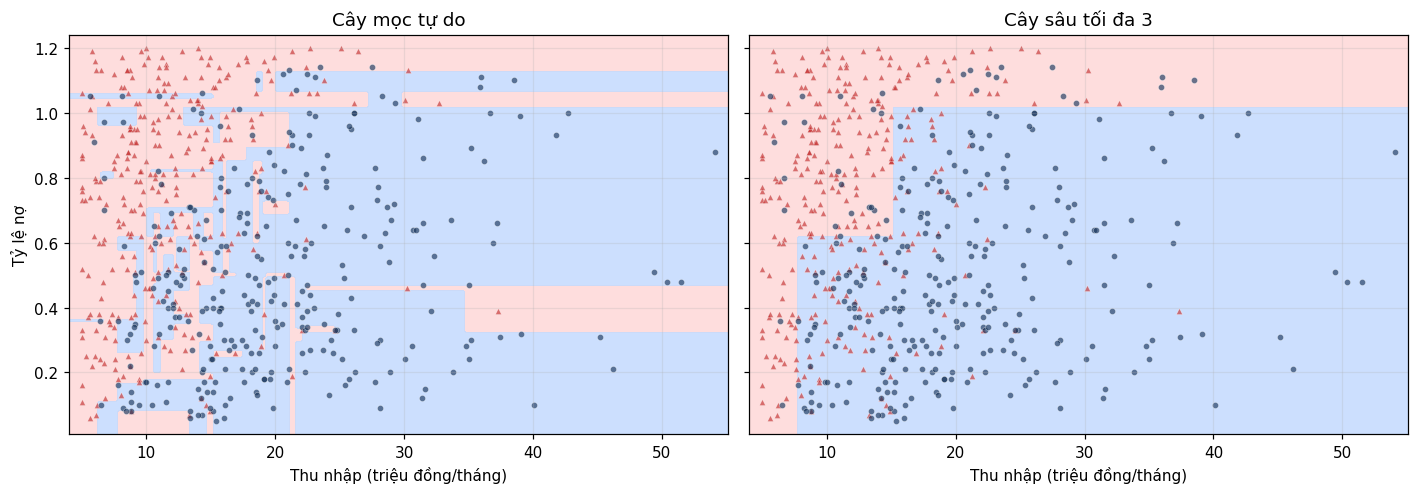

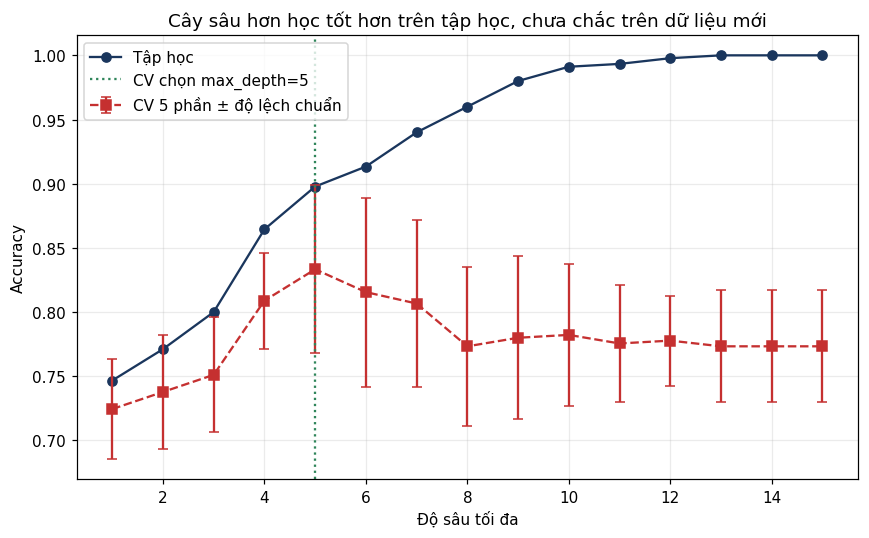

In [7]:
def ve_bien(ax, mo_hinh, X, y):
    """Chỉ dùng cho mô hình được học trên hai cột thu nhập và tỷ lệ nợ."""
    a = np.linspace(X['thu_nhap'].min()-1, X['thu_nhap'].max()+1, 200)
    b = np.linspace(X['ty_le_no'].min()-0.04, X['ty_le_no'].max()+0.04, 180)
    xx, yy = np.meshgrid(a, b)
    luoi = pd.DataFrame({'thu_nhap': xx.ravel(), 'ty_le_no': yy.ravel()})
    zz = mo_hinh.predict(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#fed7d7', '#c3dafe'], alpha=0.85)
    for nhan, mau, dau in [(0, MAU_0, '^'), (1, MAU_1, 'o')]:
        chon = y == nhan
        ax.scatter(X.loc[chon, 'thu_nhap'], X.loc[chon, 'ty_le_no'], c=mau,
                   marker=dau, s=16, alpha=0.65, edgecolors='white', linewidths=0.3)
    ax.set_xlabel('Thu nhập (triệu đồng/tháng)')


hai_cot = ['thu_nhap', 'ty_le_no']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, do_sau, ten in zip(axes, [None, 3], ['Cây mọc tự do', 'Cây sâu tối đa 3']):
    mh_2d = DecisionTreeClassifier(max_depth=do_sau, random_state=0).fit(X_tr[hai_cot], y_tr)
    ve_bien(ax, mh_2d, X_khach[hai_cot], y_khach)
    ax.set_title(ten)
axes[0].set_ylabel('Tỷ lệ nợ')
plt.tight_layout()
luu_hinh('hinh3_bien_quyet_dinh_do_sau.png')

plt.figure()
plt.plot(bang_do_sau['max_depth'], bang_do_sau['accuracy_hoc'], 'o-', color=MAU_1, label='Tập học')
plt.errorbar(bang_do_sau['max_depth'], bang_do_sau['cv_mean'], yerr=bang_do_sau['cv_std'],
             fmt='s--', color=MAU_0, capsize=3, label='CV 5 phần ± độ lệch chuẩn')
plt.axvline(d_tot, color=MAU_XANH, linestyle=':', label=f'CV chọn max_depth={d_tot}')
plt.xlabel('Độ sâu tối đa')
plt.ylabel('Accuracy')
plt.title('Cây sâu hơn học tốt hơn trên tập học, chưa chắc trên dữ liệu mới')
plt.legend()
plt.tight_layout()
luu_hinh('hinh4_chon_do_sau.png')

**Kết quả thực chạy:** cây tự do sâu 13, có 92 lá, accuracy học 1.0000 nhưng kiểm tra chỉ 0.7667. CV chọn **độ sâu 5**, điểm trung bình 0.8333; cây còn 27 lá và đạt **0.8533** trên tập kiểm tra.

**Nhận xét:** đối chiếu accuracy tập học với CV để phát hiện quá khớp; không chọn độ sâu từ điểm
kiểm tra. Độ lệch chuẩn giữa 5 phần phản ánh độ dao động, không phải khoảng tin cậy.

Hình biên quyết định dùng các mô hình **học riêng trên hai đặc trưng**, giúp nhìn rõ các ô chữ nhật;
không phải biên đầy đủ của mô hình bốn đặc trưng được chấm ở bảng trên. `max_depth`,
`max_leaf_nodes`, `min_samples_leaf`, `min_samples_split` đều là cách ngăn cây phát triển quá mức.

---
## Bước 4 — Cây không cần chuẩn hoá *(Mục 5, `f4_khong_chuan_hoa.py`)*

So ba cây sâu 5: dữ liệu gốc, chuẩn hoá bằng `StandardScaler`, đổi thu nhập từ triệu sang nghìn
đồng. Bộ chuẩn hoá chỉ được `fit` trên tập học để tránh rò rỉ dữ liệu.

,cach_do,accuracy,so_du_doan_khac_goc,nguong_goc
0,Dữ liệu gốc,0.8533,0,15.0500
1,StandardScaler,0.8533,0,-0.1039
2,Thu nhập nghìn đồng,0.8533,0,15050.0000


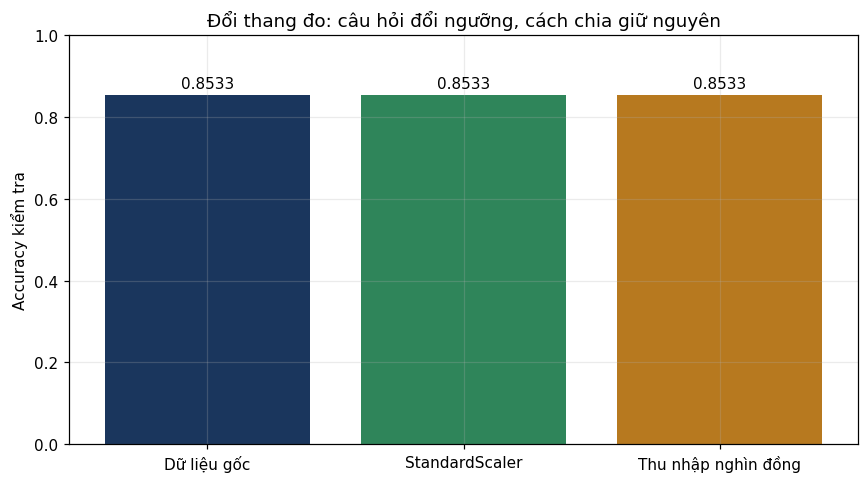

In [8]:
cay_goc = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_tr, y_tr)
scaler = StandardScaler().fit(X_tr)
cay_chuan = DecisionTreeClassifier(max_depth=5, random_state=0).fit(scaler.transform(X_tr), y_tr)
X_tr_nghin, X_te_nghin = X_tr.copy(), X_te.copy()
X_tr_nghin['thu_nhap'] *= 1000
X_te_nghin['thu_nhap'] *= 1000
cay_nghin = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_tr_nghin, y_tr)
du_goc = cay_goc.predict(X_te)
bang_chuan = []
for ten, mh, du_lieu in [('Dữ liệu gốc', cay_goc, X_te),
                         ('StandardScaler', cay_chuan, scaler.transform(X_te)),
                         ('Thu nhập nghìn đồng', cay_nghin, X_te_nghin)]:
    du_doan = mh.predict(du_lieu)
    bang_chuan.append({'cach_do': ten, 'accuracy': accuracy_score(y_te, du_doan),
                       'so_du_doan_khac_goc': int((du_doan != du_goc).sum()),
                       'nguong_goc': mh.tree_.threshold[0]})
display(pd.DataFrame(bang_chuan).round(4))

plt.figure(figsize=(8, 4.5))
cot = plt.bar([r['cach_do'] for r in bang_chuan], [r['accuracy'] for r in bang_chuan],
              color=[MAU_1, MAU_XANH, '#b7791f'])
plt.bar_label(cot, fmt='%.4f', padding=3)
plt.ylim(0, 1)
plt.ylabel('Accuracy kiểm tra')
plt.title('Đổi thang đo: câu hỏi đổi ngưỡng, cách chia giữ nguyên')
plt.tight_layout()
luu_hinh('hinh5_khong_can_chuan_hoa.png')

**Kết quả thực chạy:** cả ba cách cùng đạt **0.8533**, không khách kiểm tra nào bị dự đoán khác. Ngưỡng gốc từ 15.05 triệu đồng thành 15050 nghìn đồng.

**Giải thích:** cây so từng cột với một ngưỡng, không cộng khoảng cách giữa các cột như KNN.
Nhân thu nhập với 1000 giữ thứ tự các mẫu và đổi ngưỡng từ 15.05 sang 15050.
Chuẩn hoá tuyến tính với hệ số dương cũng giữ thứ tự nên về nguyên lý giữ các phép chia.
Trong tính toán hữu hạn, làm tròn và cách xử lý trường hợp hòa có thể tạo khác biệt nhỏ;
hãy đọc cột số dự đoán khác thay vì mặc định mọi dữ liệu đều cho kết quả tuyệt đối giống nhau.

---
## Bước 5 — Trồng rừng ngẫu nhiên *(Mục 6, `f5_rung.py`)*

Mỗi cây học trên một mẫu **bootstrap** (bốc có hoàn lại) và tại mỗi nút chỉ xét một tập cột ngẫu
nhiên. Mặc định bộ phân loại xét `sqrt(4)=2` đặc trưng mỗi nút. Tính đa dạng giữa các cây giúp
giảm phương sai khi gộp dự đoán.

Trong scikit-learn, bộ phân loại rừng lấy **trung bình xác suất các cây**, rồi chọn lớp có xác suất
lớn nhất; cách này gần ý tưởng bỏ phiếu nhưng không luôn giống đếm nhãn cứng của từng cây.

Bốc 450 lần: 286 khách khác nhau (64%)


,mo_hinh,accuracy_hoc,accuracy_kiem_tra
0,Cây tự do,1.0000,0.7667
1,Cây sâu 5 (CV),0.8978,0.8533
2,Rừng 200 cây,1.0000,0.9000


,so_cay,accuracy_kiem_tra
0,1,0.7933
1,10,0.8467
2,50,0.8733
3,200,0.9000
4,400,0.9000


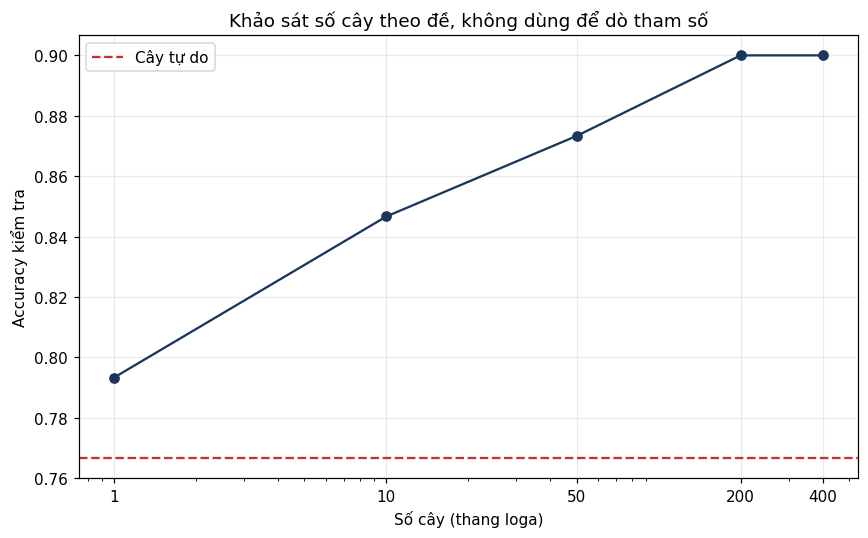

In [9]:
rng_bootstrap = np.random.default_rng(0)
chi_so = rng_bootstrap.integers(0, len(X_tr), len(X_tr))
so_khach_khac = len(np.unique(chi_so))
print(f'Bốc {len(X_tr)} lần: {so_khach_khac} khách khác nhau ({so_khach_khac/len(X_tr):.0%})')

rung = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_tr, y_tr)
bang_mo_hinh = []
for ten, mh in [('Cây tự do', cay_tu_do), (f'Cây sâu {d_tot} (CV)', cay_tot), ('Rừng 200 cây', rung)]:
    bang_mo_hinh.append({'mo_hinh': ten, 'accuracy_hoc': mh.score(X_tr, y_tr),
                         'accuracy_kiem_tra': mh.score(X_te, y_te)})
display(pd.DataFrame(bang_mo_hinh).round(4))

# Khảo sát theo các giá trị đã định trong đề; không chọn số cây theo tập kiểm tra.
bang_so_cay = []
for so_cay in [1, 10, 50, 200, 400]:
    mh = rung if so_cay == 200 else RandomForestClassifier(
        n_estimators=so_cay, random_state=0).fit(X_tr, y_tr)
    bang_so_cay.append({'so_cay': so_cay, 'accuracy_kiem_tra': mh.score(X_te, y_te)})
bang_so_cay = pd.DataFrame(bang_so_cay)
display(bang_so_cay.round(4))

plt.figure()
plt.plot(bang_so_cay['so_cay'], bang_so_cay['accuracy_kiem_tra'], 'o-', color=MAU_1)
plt.axhline(cay_tu_do.score(X_te, y_te), color=MAU_0, linestyle='--', label='Cây tự do')
plt.xscale('log')
plt.xticks([1, 10, 50, 200, 400], [1, 10, 50, 200, 400])
plt.xlabel('Số cây (thang loga)')
plt.ylabel('Accuracy kiểm tra')
plt.title('Khảo sát số cây theo đề, không dùng để dò tham số')
plt.legend()
plt.tight_layout()
luu_hinh('hinh6_so_cay_trong_rung.png')

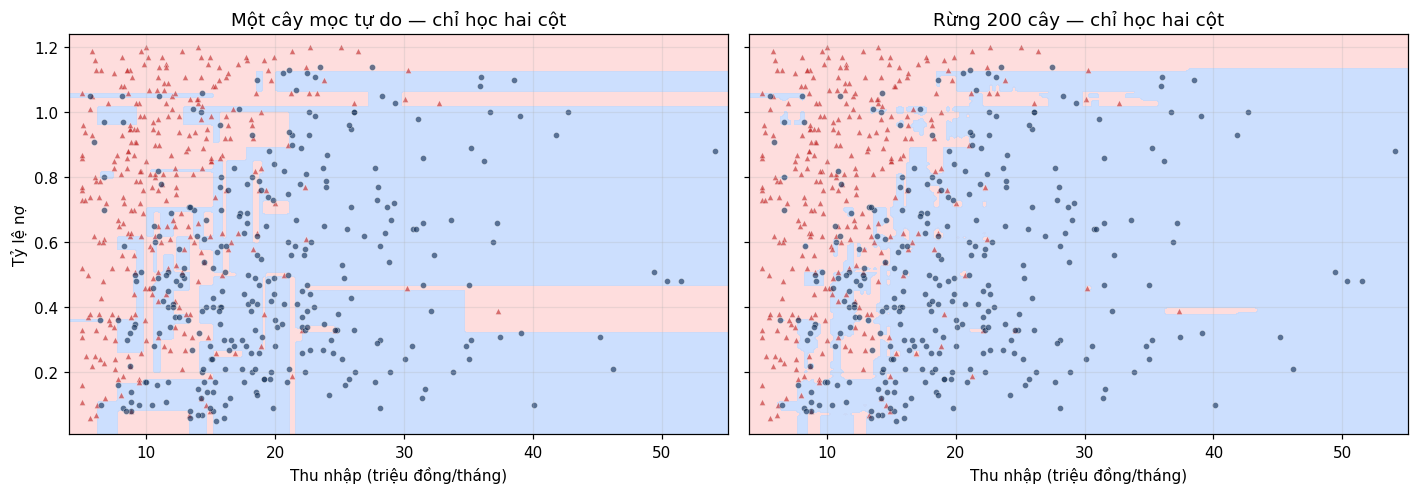

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, mh, ten in zip(axes,
                       [DecisionTreeClassifier(random_state=0),
                        RandomForestClassifier(n_estimators=200, random_state=0)],
                       ['Một cây mọc tự do', 'Rừng 200 cây']):
    mh.fit(X_tr[hai_cot], y_tr)
    ve_bien(ax, mh, X_khach[hai_cot], y_khach)
    ax.set_title(ten + ' — chỉ học hai cột')
axes[0].set_ylabel('Tỷ lệ nợ')
plt.tight_layout()
luu_hinh('hinh7_bien_cay_va_rung.png')

**Kết quả thực chạy:** rừng 200 cây đạt **0.9000**, so với cây tự do 0.7667 và cây sâu 5 0.8533. Tăng từ 200 lên 400 cây vẫn đạt 0.9000 trên lần chia này.

**Nhận xét:** bốc có hoàn lại khiến nhiều khách lặp lại và một số khách không xuất hiện trong một
cây; số khách phân biệt trung bình xấp xỉ 63.2% khi cỡ mẫu lớn. Thêm cây thường làm dự đoán ổn định
hơn, lợi ích giảm dần và tốn thời gian/bộ nhớ hơn; accuracy trên một tập kiểm tra hữu hạn vẫn có
thể dao động, không được bảo đảm tăng đều.

Rừng có thể đạt accuracy học 1.0 mà tổng quát hóa tốt hơn cây đơn. Đổi lại, khó đọc toàn bộ rừng
thành một chuỗi luật ngắn như cây năm lá.

---
## Bước 6 — Độ quan trọng và cột ngẫu nhiên *(Mục 7, `f6_do_quan_trong.py`)*

`feature_importances_` đo mức giảm độ hỗn tạp có trọng số do từng đặc trưng tạo ra, tổng bằng 1.
Thử thêm một cột số ngẫu nhiên không mang tín hiệu để thấy giới hạn của cách đo trên tập học.

Bốn cột thật:


thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Name: MDI, dtype: float64

Tổng: 1.000


Thêm cột ngẫu nhiên:


thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076
Name: MDI, dtype: float64

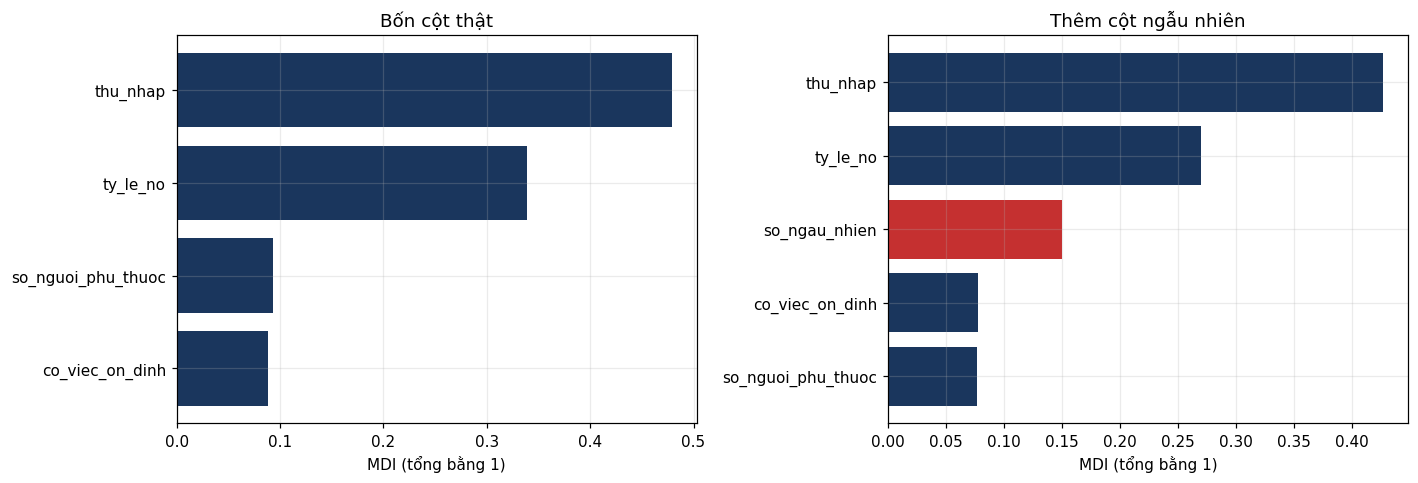

In [11]:
qt = pd.Series(rung.feature_importances_, index=cot_khach, name='MDI')
print('Bốn cột thật:')
display(qt.sort_values(ascending=False).round(3))
print(f'Tổng: {qt.sum():.3f}')

rng_nhieu = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn['so_ngau_nhien'] = rng_nhieu.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_tr_nn, y_tr)
qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns, name='MDI')
print('Thêm cột ngẫu nhiên:')
display(qt_nn.sort_values(ascending=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, do_quan_trong, ten in zip(axes, [qt, qt_nn], ['Bốn cột thật', 'Thêm cột ngẫu nhiên']):
    sap = do_quan_trong.sort_values()
    ax.barh(sap.index, sap.values,
            color=[MAU_0 if c == 'so_ngau_nhien' else MAU_1 for c in sap.index])
    ax.set_xlabel('MDI (tổng bằng 1)')
    ax.set_title(ten)
plt.tight_layout()
luu_hinh('hinh8_do_quan_trong_mdi.png')

**Kết quả thực chạy:** thu nhập có MDI 0.479, tỷ lệ nợ 0.339. Khi thêm cột nhiễu, `so_ngau_nhien` có MDI **0.150**, đứng thứ 3, cao hơn hai cột thật còn lại.

**Giải thích:** cột liên tục có nhiều giá trị khác nhau cung cấp nhiều ngưỡng để thử, nên dễ tìm
được một phép chia làm giảm Gini trên tập học kể cả khi chỉ khớp nhiễu. Cột nhị phân chỉ có một
ngưỡng hữu ích. Vì vậy MDI cao không tự chứng minh một cột hữu ích trên dữ liệu mới.

Độ quan trọng thể hiện cách **mô hình** dùng dữ liệu, không chứng minh quan hệ nhân quả.
Bài tập 5 sẽ xáo trộn từng cột trên tập kiểm tra để đo mức giảm accuracy thực tế.

---
## Bước 7 — Cây hồi quy và giới hạn ngoại suy *(Mục 8, `f7_cay_hoi_quy.py`)*

`DecisionTreeRegressor` chia dữ liệu để giảm sai số bình phương; mỗi lá dự đoán bằng giá trị
trung bình của các mẫu học trong lá. Với một đầu vào diện tích, đường dự đoán là các bậc thang.
So cây sâu 3 với hồi quy tuyến tính trên cùng cách chia của Lab1. MAE tính bằng tỷ đồng.

Kích thước dữ liệu nhà: (60, 4)
Khoảng diện tích tập học: 37.6 đến 117.5
Cây sâu 3 có 8 lá
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE cây: 0.5039 tỷ; đường thẳng: 0.2578 tỷ


,dien_tich,cay,duong_thang
0,60.0,4.9212,5.1249
1,100.0,8.3160,8.2384
2,150.0,9.4025,12.1303
3,250.0,9.4025,19.9139


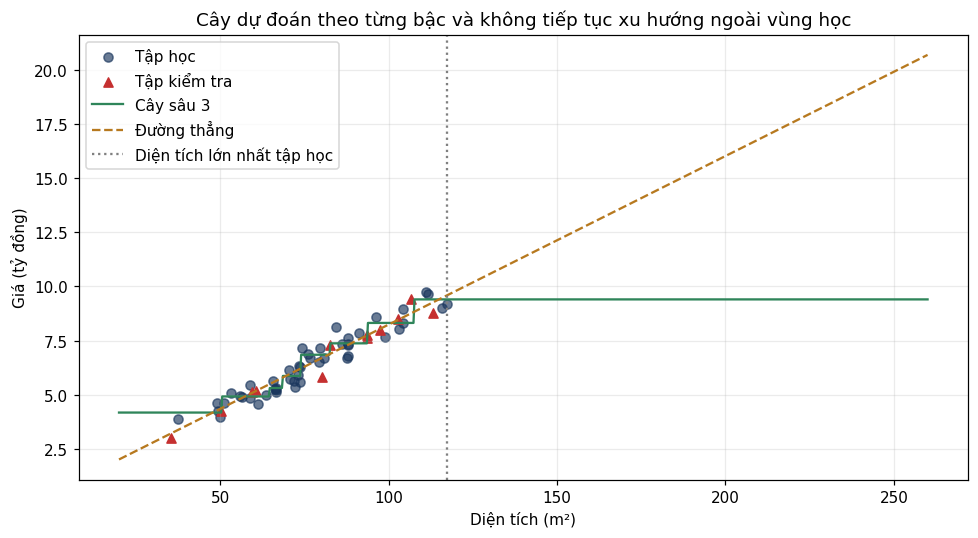

In [12]:
nha = pd.read_csv(tim_tep('gia_nha.csv'))
assert not nha.isna().any().any()
X_nha, y_nha = nha[['dien_tich']], nha['gia']
X_tr_nha, X_te_nha, y_tr_nha, y_te_nha = train_test_split(
    X_nha, y_nha, test_size=0.2, random_state=42)
cay_hoi_quy = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_tr_nha, y_tr_nha)
duong_thang = LinearRegression().fit(X_tr_nha, y_tr_nha)
print('Kích thước dữ liệu nhà:', nha.shape)
print('Khoảng diện tích tập học:', X_tr_nha['dien_tich'].min(), 'đến', X_tr_nha['dien_tich'].max())
print(f'Cây sâu 3 có {cay_hoi_quy.get_n_leaves()} lá')
print(export_text(cay_hoi_quy, feature_names=['dien_tich'], decimals=1))
mae_cay = mean_absolute_error(y_te_nha, cay_hoi_quy.predict(X_te_nha))
mae_duong = mean_absolute_error(y_te_nha, duong_thang.predict(X_te_nha))
print(f'MAE cây: {mae_cay:.4f} tỷ; đường thẳng: {mae_duong:.4f} tỷ')
can_moi = pd.DataFrame({'dien_tich': [60.0, 100.0, 150.0, 250.0]})
display(can_moi.assign(cay=cay_hoi_quy.predict(can_moi),
                       duong_thang=duong_thang.predict(can_moi)).round(4))

luoi_nha = pd.DataFrame({'dien_tich': np.linspace(20, 260, 800)})
plt.figure(figsize=(9, 5))
plt.scatter(X_tr_nha['dien_tich'], y_tr_nha, color=MAU_1, alpha=0.65, label='Tập học')
plt.scatter(X_te_nha['dien_tich'], y_te_nha, color=MAU_0, marker='^', label='Tập kiểm tra')
plt.plot(luoi_nha['dien_tich'], cay_hoi_quy.predict(luoi_nha), color=MAU_XANH, label='Cây sâu 3')
plt.plot(luoi_nha['dien_tich'], duong_thang.predict(luoi_nha), '--', color='#b7791f', label='Đường thẳng')
plt.axvline(X_tr_nha['dien_tich'].max(), color='gray', linestyle=':', label='Diện tích lớn nhất tập học')
plt.xlabel('Diện tích (m²)')
plt.ylabel('Giá (tỷ đồng)')
plt.title('Cây dự đoán theo từng bậc và không tiếp tục xu hướng ngoài vùng học')
plt.legend()
plt.tight_layout()
luu_hinh('hinh9_cay_hoi_quy.png')

**Kết quả thực chạy:** MAE cây sâu 3 là **0.5039 tỷ**, đường thẳng là **0.2578 tỷ**. Cây dự đoán cùng **9.4025 tỷ** cho cả 150 m² và 250 m².

**Nhận xét:** dữ liệu giá nhà có xu hướng gần tuyến tính nên đường thẳng có thể thắng cây sâu 3.
Căn 150 m² và 250 m² đều đi vào lá ngoài cùng bên phải và nhận cùng một mức giá. Cây không
kéo dài xu hướng theo diện tích. Hồi quy tuyến tính kéo dài đường thẳng được, nhưng điều đó
không bảo đảm dự đoán ngoài miền dữ liệu là đáng tin.

---
# Phần B — Bài tập

Các lời giải dưới đây dùng lại biến đã chuẩn bị ở phần A; chạy notebook từ đầu để tái lập kết quả.

## Bài tập 1 — Tự vẽ cây

Vẽ cây năm lá, lưu đúng tên `cay_nam_la.png`; sau đó học cây mới với `max_depth=2`.
Vẽ riêng để thấy việc giới hạn độ sâu khi **học** khác với chỉ cắt bớt phần hiển thị của cây sâu.

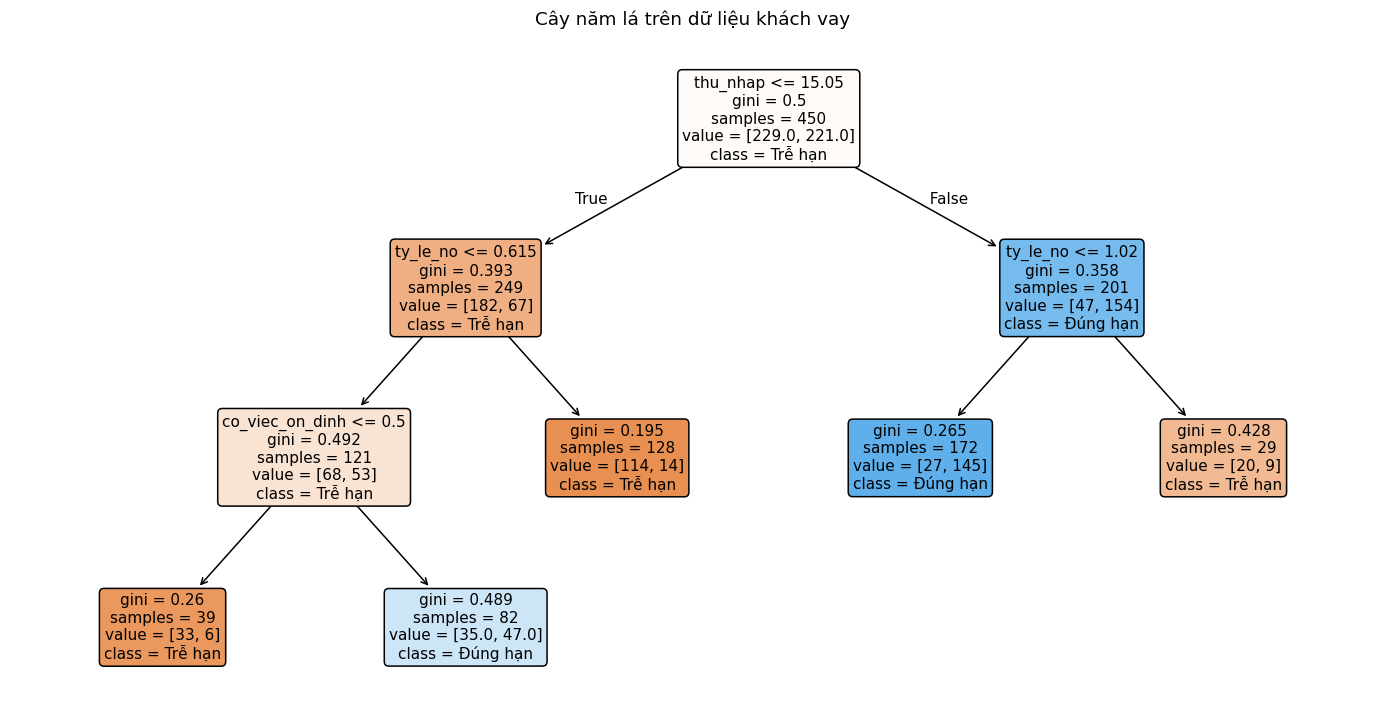

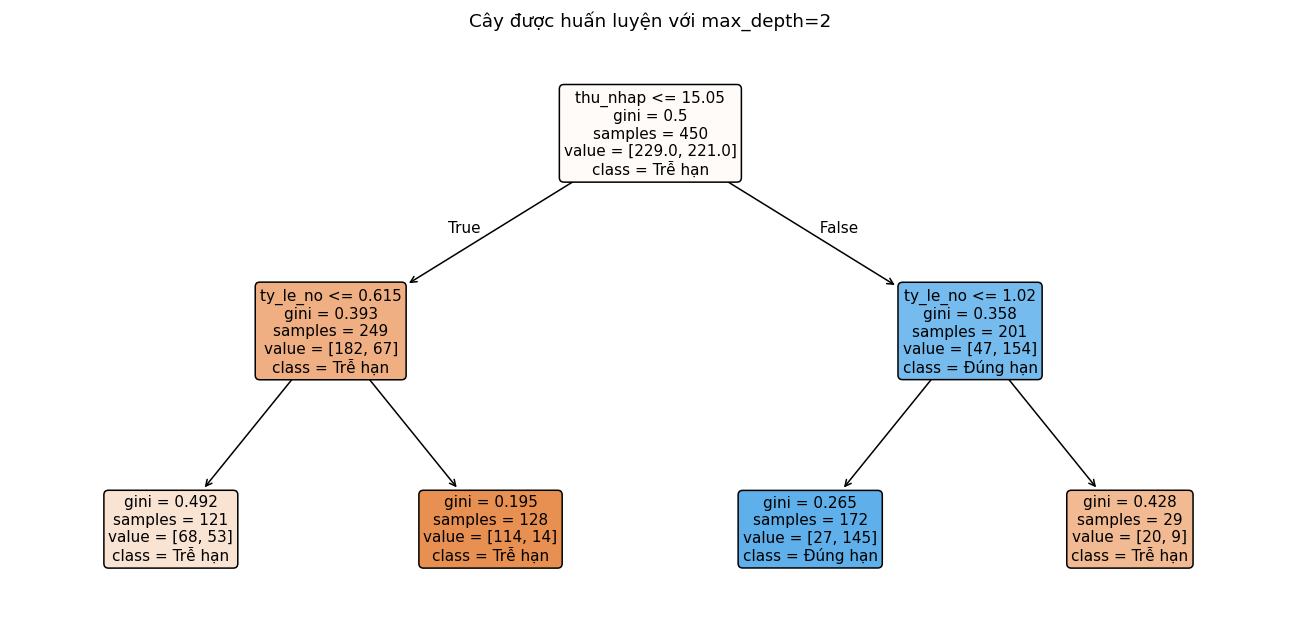

|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- weights: [68.000, 53.000] class: 0
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Lá 2: nhãn 0, tỷ lệ đúng hạn 0.4380, Gini 0.4923, số khách 121
Lá 3: nhãn 0, tỷ lệ đúng hạn 0.1094, Gini 0.1948, số khách 128
Gini nhánh trái: 0.3933 → 0.3394


In [13]:
plt.figure(figsize=(16, 8))
plot_tree(cay_nam_la, feature_names=cot_khach, class_names=['Trễ hạn', 'Đúng hạn'],
          filled=True, rounded=True, precision=3, fontsize=10)
plt.title('Cây năm lá trên dữ liệu khách vay')
luu_hinh('cay_nam_la.png')

cay_sau_2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
plt.figure(figsize=(15, 7))
plot_tree(cay_sau_2, feature_names=cot_khach, class_names=['Trễ hạn', 'Đúng hạn'],
          filled=True, rounded=True, precision=3, fontsize=10)
plt.title('Cây được huấn luyện với max_depth=2')
luu_hinh('cay_sau_2.png')
print(export_text(cay_sau_2, feature_names=cot_khach, show_weights=True, decimals=3))

# Đọc hai lá con của nhánh trái trực tiếp từ cây, không giả định mã số nút.
cau_truc = cay_sau_2.tree_
nut_trai = cau_truc.children_left[0]
hai_la_trai = [cau_truc.children_left[nut_trai], cau_truc.children_right[nut_trai]]
for la in hai_la_trai:
    dem = cau_truc.value[la][0]
    nhan = cay_sau_2.classes_[dem.argmax()]
    print(f'Lá {la}: nhãn {nhan}, tỷ lệ đúng hạn {dem[1]/dem.sum():.4f}, '
          f'Gini {cau_truc.impurity[la]:.4f}, số khách {cau_truc.n_node_samples[la]}')
g_sau = sum(cau_truc.n_node_samples[la] * cau_truc.impurity[la] for la in hai_la_trai)
g_sau /= cau_truc.n_node_samples[nut_trai]
print(f'Gini nhánh trái: {cau_truc.impurity[nut_trai]:.4f} → {g_sau:.4f}')

**Kết quả thực chạy:** hai lá bên trái có tỷ lệ đúng hạn **53/121 = 0.4380** và **14/128 = 0.1094**; Gini của nhánh trái giảm từ **0.3933** xuống **0.3394** sau chia.

**Trả lời:** hai lá bên trái cùng kết luận **trễ hạn**. Cây vẫn chia vì tỷ lệ đúng hạn của hai nhóm
khác nhau, làm Gini có trọng số giảm. Nhãn dự đoán chỉ là lớp chiếm đa số; hai nhóm cùng nhãn
không có nghĩa là cùng phân bố xác suất. Thuật toán tối ưu độ thuần, không đòi mỗi phép chia
phải làm hai nhãn dự đoán khác nhau.

## Bài tập 2 — Tự tìm câu hỏi gốc trên 450 khách

Hàm `tim_cau_hoi(X, y)` thử **mọi cột, mọi trung điểm giữa hai giá trị phân biệt liền nhau**,
tính Gini có trọng số và trả về phép chia tốt nhất. Chỉ dùng NumPy/pandas trong quá trình tìm;
sau đó so với gốc cây scikit-learn để kiểm chứng.

In [14]:
def tim_cau_hoi(X, y):
    """Trả về cột, ngưỡng, Gini sau chia và mức giảm lớn nhất cho nhãn 0/1."""
    nhan = np.asarray(y)
    if len(X) != len(nhan) or len(nhan) == 0:
        raise ValueError('X và y phải cùng số dòng và không rỗng.')
    if X.isna().any().any() or not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError('Các đặc trưng phải là số hữu hạn, không thiếu.')
    if not np.isin(nhan, [0, 1]).all():
        raise ValueError('Hàm này dành cho nhãn nhị phân 0/1.')
    goc, tot = gini(nhan), None
    for cot in X.columns:
        gia_tri = X[cot].to_numpy(dtype=float)
        muc = np.unique(gia_tri)
        for nguong in (muc[:-1] + muc[1:]) / 2:
            di_trai = gia_tri <= nguong
            g_chia = gini_sau_chia(nhan, di_trai)
            giam = goc - g_chia
            if tot is None or giam > tot['gini_giam']:
                tot = {'cot': cot, 'nguong': float(nguong), 'gini_sau_chia': g_chia,
                       'gini_giam': giam, 'n_trai': int(di_trai.sum()),
                       'n_phai': int((~di_trai).sum())}
    if tot is None:
        raise ValueError('Không có ngưỡng chia: mọi cột đều hằng số.')
    return tot


cau_hoi_tot = tim_cau_hoi(X_tr, y_tr)
print('Tự tìm:', cau_hoi_tot)
cot_sklearn = cot_khach[cay_nam_la.tree_.feature[0]]
nguong_sklearn = cay_nam_la.tree_.threshold[0]
print(f'scikit-learn: {cot_sklearn} <= {nguong_sklearn:.5f}')
assert cau_hoi_tot['cot'] == cot_sklearn == 'thu_nhap'
assert np.isclose(cau_hoi_tot['nguong'], nguong_sklearn, atol=1e-5)
assert np.isclose(cau_hoi_tot['nguong'], 15.05)

# Liệt kê phép chia tốt nhất của từng cột để giải thích vì sao chọn thu nhập.
tot_tung_cot = pd.DataFrame([tim_cau_hoi(X_tr[[cot]], y_tr) for cot in cot_khach])
display(tot_tung_cot.sort_values('gini_giam', ascending=False).round(5))

Tự tìm: {'cot': 'thu_nhap', 'nguong': 15.05, 'gini_sau_chia': 0.3776970568842535, 'gini_giam': 0.1221449184243884, 'n_trai': 249, 'n_phai': 201}
scikit-learn: thu_nhap <= 15.05000


,cot,nguong,gini_sau_chia,gini_giam,n_trai,n_phai
0,thu_nhap,15.050,0.37770,0.12214,249,201
1,ty_le_no,0.605,0.44123,0.05862,227,223
2,co_viec_on_dinh,0.500,0.46691,0.03293,149,301
3,so_nguoi_phu_thuoc,2.500,0.47637,0.02347,250,200


**Kết quả thực chạy:** ngưỡng **15.05** chia thành 249 khách bên trái, 201 bên phải; Gini sau chia **0.37770**, giảm **0.12214**. Ngưỡng tốt nhất của tỷ lệ nợ chỉ giảm 0.05862, việc làm 0.03293, số người phụ thuộc 0.02347.

**Giải thích:** thu nhập với ngưỡng **15.05 triệu/tháng** có mức giảm Gini lớn nhất trong mọi
câu hỏi được thử. Ngưỡng nằm giữa hai mức thu nhập kế tiếp; thay ngưỡng trong khoảng đó không
đổi cách chia khách học. Không chọn cột theo tương quan hoặc chọn ngưỡng theo cảm tính.

Cần lấy trung bình Gini **có trọng số**: bỏ trọng số sẽ đánh giá sai các cách chia lệch kích thước.
Hàm mới tìm câu hỏi **gốc**, chưa xây cả cây; ở nút con phải tìm lại trên tập con tương ứng.
Gốc cây đơn trong đề trùng nhau vì cùng dữ liệu, tiêu chí và các giới hạn không cản câu hỏi này;
gốc từng cây trong rừng không bắt buộc trùng vì bootstrap và lựa chọn đặc trưng ngẫu nhiên.
Sai khác rất nhỏ ở chữ số cuối của ngưỡng scikit-learn có thể do biểu diễn float32.

## Bài tập 3 — Gini hay entropy?

Giữ nguyên tập học/kiểm tra và dải độ sâu 1–15. Chọn độ sâu cho mỗi tiêu chí bằng CV trên tập học,
rồi chấm mô hình đã chọn trên tập kiểm tra. Với entropy, độ hỗn tạp là
$H=-\sum_k p_k\log_2 p_k$, quy ước $0\log_2 0=0$.

,tieu_chi,do_sau_tot,cv_mean,accuracy_kiem_tra
0,gini,5,0.8333,0.8533
1,entropy,5,0.8222,0.8467


Chênh accuracy kiểm tra: 0.0067 (0.67 điểm phần trăm)


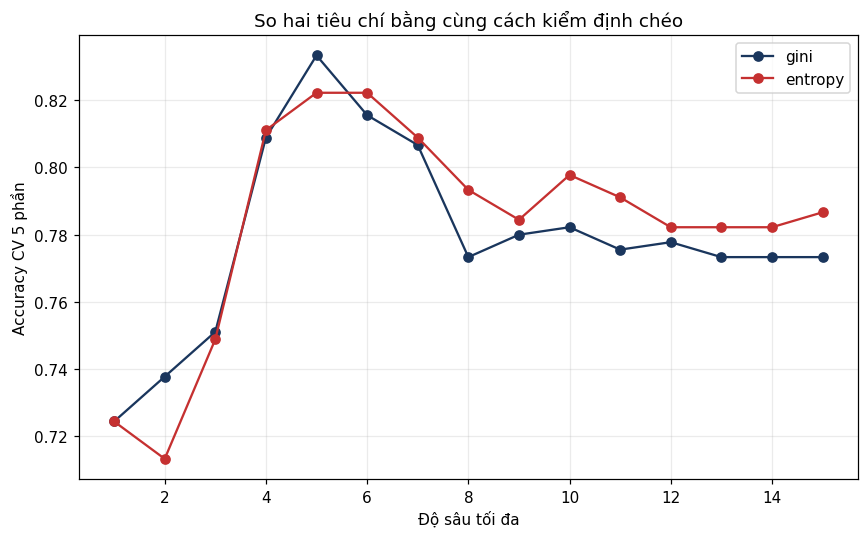

In [15]:
bang_tieu_chi, duong_cv = [], {}
for tieu_chi in ['gini', 'entropy']:
    diem = {}
    for d in range(1, 16):
        diem[d] = cross_val_score(
            DecisionTreeClassifier(criterion=tieu_chi, max_depth=d, random_state=0),
            X_tr, y_tr, cv=5, scoring='accuracy').mean()
    d_chon = max(diem, key=diem.get)
    mh = DecisionTreeClassifier(criterion=tieu_chi, max_depth=d_chon, random_state=0).fit(X_tr, y_tr)
    bang_tieu_chi.append({'tieu_chi': tieu_chi, 'do_sau_tot': d_chon,
                          'cv_mean': diem[d_chon], 'accuracy_kiem_tra': mh.score(X_te, y_te)})
    duong_cv[tieu_chi] = diem
bang_tieu_chi = pd.DataFrame(bang_tieu_chi)
display(bang_tieu_chi.round(4))
chenh = abs(bang_tieu_chi.loc[0, 'accuracy_kiem_tra'] - bang_tieu_chi.loc[1, 'accuracy_kiem_tra'])
print(f'Chênh accuracy kiểm tra: {chenh:.4f} ({chenh*100:.2f} điểm phần trăm)')

plt.figure()
for ten, mau in [('gini', MAU_1), ('entropy', MAU_0)]:
    plt.plot(list(duong_cv[ten]), list(duong_cv[ten].values()), 'o-', label=ten, color=mau)
plt.xlabel('Độ sâu tối đa')
plt.ylabel('Accuracy CV 5 phần')
plt.title('So hai tiêu chí bằng cùng cách kiểm định chéo')
plt.legend()
plt.tight_layout()
luu_hinh('hinh10_gini_entropy.png')

**Kết quả thực chạy:** cả hai tiêu chí chọn độ sâu **5**. Gini có CV 0.8333, accuracy kiểm tra **0.8533**; entropy có CV 0.8222, accuracy **0.8467**. Chênh chỉ **0.67 điểm phần trăm** (1 khách trong 150), nên đổi tiêu chí không làm kết quả khác nhiều ở lần chia này.

**Nhận xét:** cả Gini và entropy đều ưu tiên các nhánh thuần; phép chia cụ thể và độ sâu được
chọn vẫn có thể khác. Đọc độ chênh in ở trên để nhận xét trên bộ dữ liệu này; không thể kết luận
một tiêu chí luôn tốt hơn từ một lần chia 600 hồ sơ.

## Bài tập 4 — Cắt tỉa bằng số khách tối thiểu ở lá

Giữ `max_depth=None`, thử `min_samples_leaf` trong `[1, 2, 5, 10, 20, 40]`.
Giá trị tối ưu lấy từ CV; không chọn dựa vào accuracy kiểm tra. So với cây sâu 5 của Mục 4.

In [16]:
bang_la = []
for so_khach_la in [1, 2, 5, 10, 20, 40]:
    mh = DecisionTreeClassifier(min_samples_leaf=so_khach_la, random_state=0)
    cv = cross_val_score(mh, X_tr, y_tr, cv=5, scoring='accuracy')
    bang_la.append({'min_samples_leaf': so_khach_la, 'cv_mean': cv.mean(), 'cv_std': cv.std()})
bang_la = pd.DataFrame(bang_la)
la_tot = int(bang_la.loc[bang_la['cv_mean'].idxmax(), 'min_samples_leaf'])
cay_la_tot = DecisionTreeClassifier(min_samples_leaf=la_tot, random_state=0).fit(X_tr, y_tr)
display(bang_la.round(4))
so_sanh_tia = pd.DataFrame([
    {'cach_tia': f'min_samples_leaf={la_tot}', 'do_sau': cay_la_tot.get_depth(),
     'so_la': cay_la_tot.get_n_leaves(), 'accuracy_kiem_tra': cay_la_tot.score(X_te, y_te)},
    {'cach_tia': 'max_depth=5', 'do_sau': cay_goc.get_depth(),
     'so_la': cay_goc.get_n_leaves(), 'accuracy_kiem_tra': cay_goc.score(X_te, y_te)},
])
display(so_sanh_tia.round(4))
a_la, a_sau = so_sanh_tia['accuracy_kiem_tra']
print('Kết quả trên tập kiểm tra:', 'Hai cách bằng nhau' if np.isclose(a_la, a_sau)
      else ('Giới hạn số khách ở lá tốt hơn' if a_la > a_sau else 'Giới hạn độ sâu 5 tốt hơn'))

,min_samples_leaf,cv_mean,cv_std
0,1,0.7733,0.0437
1,2,0.7822,0.0694
2,5,0.8067,0.0543
3,10,0.8089,0.0381
4,20,0.8089,0.0374
5,40,0.7133,0.0594


,cach_tia,do_sau,so_la,accuracy_kiem_tra
0,min_samples_leaf=10,8,30,0.8467
1,max_depth=5,5,27,0.8533


Kết quả trên tập kiểm tra: Giới hạn độ sâu 5 tốt hơn


**Kết quả thực chạy:** `min_samples_leaf=10` và `20` cùng CV trung bình cao nhất (0.8089); lấy **10** theo thứ tự duyệt tăng dần đã định. Cây có 30 lá, sâu 8, accuracy kiểm tra **0.8467**. Cây sâu 5 đạt **0.8533**, tốt hơn 1 khách trên tập kiểm tra này.

**Giải thích:** `min_samples_leaf` ngăn các lá chỉ chứa vài khách; cây vẫn có thể đi sâu ở vùng
còn nhiều dữ liệu. `max_depth` giới hạn mọi đường đi, kể cả nhánh đang có nhiều khách.
Hai cách kiểm soát độ phức tạp khác nhau nên không nhất thiết tạo cùng cây hoặc cùng accuracy.
Kết quả so sánh ở trên là cho lần chia cố định này, không phải một quy tắc chung.

## Bài tập 5 — Độ quan trọng bằng cách xáo trộn

Giữ nguyên rừng đã học với cột ngẫu nhiên ở Bước 6. Sinh thêm một cột ngẫu nhiên độc lập cho
tập kiểm tra, dùng `permutation_importance(n_repeats=20, random_state=0, scoring='accuracy')`.
Không học lại mô hình khi xáo trộn. Điểm quan trọng là accuracy gốc trừ accuracy sau xáo trộn.

Accuracy gốc của rừng có cột ngẫu nhiên: 0.9067


,MDI,permutation_mean,permutation_std,hang_MDI,hang_permutation
thu_nhap,0.4269,0.3073,0.0242,1,1
ty_le_no,0.2696,0.1993,0.0357,2,2
co_viec_on_dinh,0.0773,0.1117,0.0155,4,3
so_nguoi_phu_thuoc,0.0764,0.0497,0.0199,5,4
so_ngau_nhien,0.1499,0.0017,0.0111,3,5


Cột ngẫu nhiên: hạng MDI 3, hạng permutation 5; mức giảm accuracy 0.0017 ± 0.0111


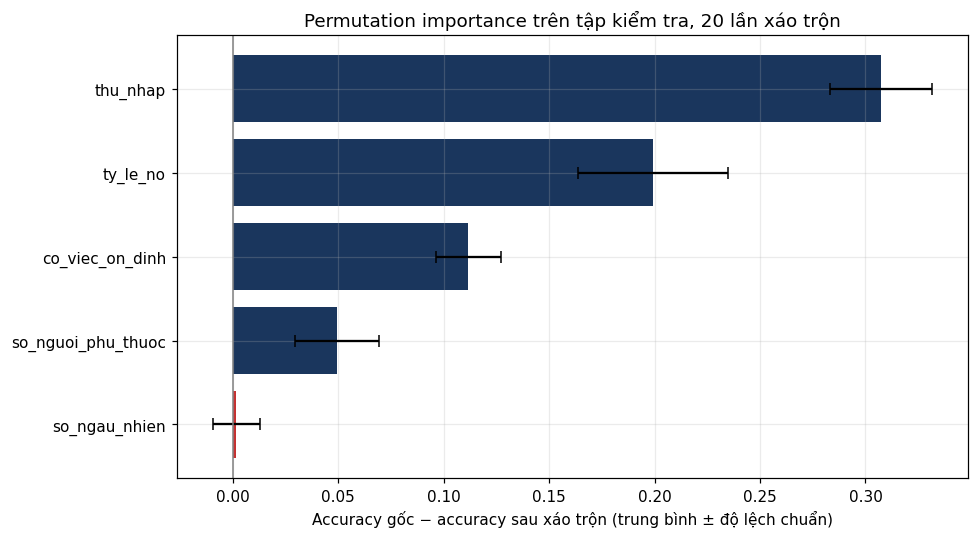

In [17]:
X_te_nn = X_te.copy()
X_te_nn['so_ngau_nhien'] = rng_nhieu.random(len(X_te))
hoan_vi = permutation_importance(
    rung_nn, X_te_nn, y_te, n_repeats=20, random_state=0, scoring='accuracy')
bang_quan_trong = pd.DataFrame({
    'MDI': qt_nn,
    'permutation_mean': hoan_vi.importances_mean,
    'permutation_std': hoan_vi.importances_std,
}, index=X_tr_nn.columns)
bang_quan_trong['hang_MDI'] = bang_quan_trong['MDI'].rank(ascending=False, method='min').astype(int)
bang_quan_trong['hang_permutation'] = bang_quan_trong['permutation_mean'].rank(
    ascending=False, method='min').astype(int)
print(f'Accuracy gốc của rừng có cột ngẫu nhiên: {rung_nn.score(X_te_nn, y_te):.4f}')
display(bang_quan_trong.sort_values('permutation_mean', ascending=False).round(4))
hang_nn = bang_quan_trong.loc['so_ngau_nhien']
print(f"Cột ngẫu nhiên: hạng MDI {int(hang_nn['hang_MDI'])}, "
      f"hạng permutation {int(hang_nn['hang_permutation'])}; "
      f"mức giảm accuracy {hang_nn['permutation_mean']:.4f} ± {hang_nn['permutation_std']:.4f}")

sap = bang_quan_trong.sort_values('permutation_mean')
plt.figure(figsize=(9, 5))
plt.barh(sap.index, sap['permutation_mean'], xerr=sap['permutation_std'], capsize=4,
         color=[MAU_0 if c == 'so_ngau_nhien' else MAU_1 for c in sap.index])
plt.axvline(0, color='gray', linewidth=1)
plt.xlabel('Accuracy gốc − accuracy sau xáo trộn (trung bình ± độ lệch chuẩn)')
plt.title('Permutation importance trên tập kiểm tra, 20 lần xáo trộn')
plt.tight_layout()
luu_hinh('hinh11_permutation_importance.png')

**Kết quả thực chạy:** cột ngẫu nhiên từ hạng **3 theo MDI** xuống hạng **5 theo permutation**; mức giảm accuracy chỉ **0.0017 ± 0.0111**, gần 0 và nhỏ so với độ dao động qua các lần xáo trộn. Thu nhập và tỷ lệ nợ vẫn đứng đầu (0.3073 và 0.1993).

**Giải thích:** MDI cộng công giảm Gini trên tập học nên cột ngẫu nhiên có nhiều ngưỡng vẫn được
điểm. Permutation kiểm tra việc phá vỡ liên hệ của cột với nhãn có làm giảm chất lượng trên
dữ liệu chưa học hay không. Cột nhiễu thường có mức giảm gần 0, có thể âm nếu xáo trộn vô tình
giúp mô hình; dấu âm không có nghĩa cột đó mang quan hệ nhân quả ngược.

Hai thước đo có đơn vị khác nhau: MDI chuẩn hoá có tổng 1, permutation là mức chênh accuracy,
không bắt buộc có tổng 1. Độ lệch chuẩn là độ dao động qua 20 lần xáo trộn trên **cùng** tập
kiểm tra. Với các cột tương quan, permutation có thể đánh giá thấp đóng góp vì cột khác thay thế
được; cả hai cách đều không chứng minh nhân quả. Không loại/chọn lại cột từ kết quả kiểm tra này
rồi tuyên bố điểm trên chính tập đó là độc lập.

## Bài tập 6 — Rừng hồi quy

Học `RandomForestRegressor(n_estimators=200, random_state=0)` trên đúng tập học giá nhà ở Bước 7.
So MAE với cây sâu 3 và đường thẳng, rồi dự đoán căn 250 m² và giải thích cơ chế từng lá.

,mo_hinh,MAE_ty_dong,gia_250_m2
0,Cây sâu 3,0.5039,9.4025
1,Rừng 200 cây,0.4559,9.1973
2,Đường thẳng,0.2578,19.9139


,dien_tich,cay,rung,duong_thang
0,60.0,4.9212,5.0911,5.1249
1,100.0,8.3160,7.8858,8.2384
2,150.0,9.4025,9.1973,12.1303
3,250.0,9.4025,9.1973,19.9139


Cả 200 cây đưa 150 và 250 m² vào cùng lá: True
Khoảng dự đoán từng cây ở 250 m²: 8.523333333333333 đến 9.74
Trung bình dự đoán các cây: 9.197249999999999


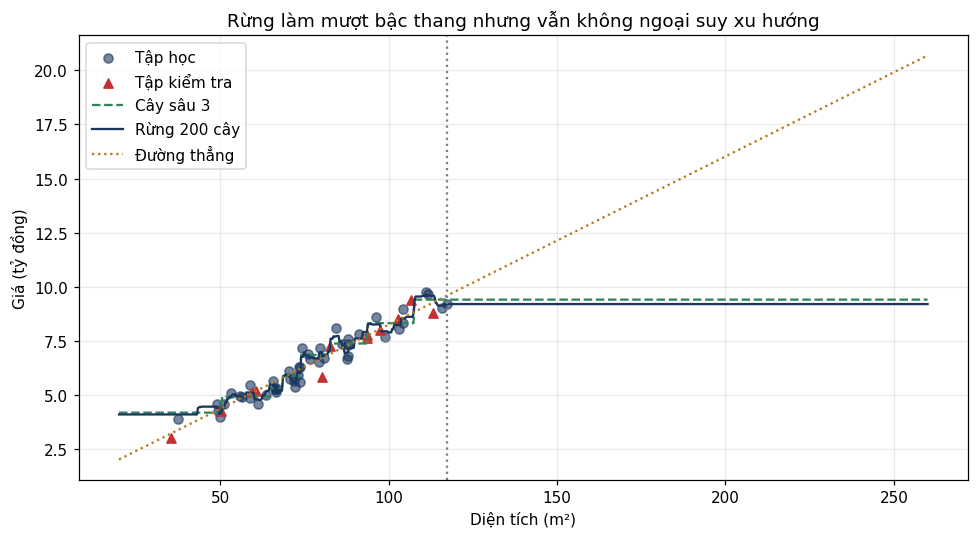

In [18]:
rung_hoi_quy = RandomForestRegressor(n_estimators=200, random_state=0).fit(X_tr_nha, y_tr_nha)
bang_hoi_quy = []
for ten, mh in [('Cây sâu 3', cay_hoi_quy), ('Rừng 200 cây', rung_hoi_quy), ('Đường thẳng', duong_thang)]:
    bang_hoi_quy.append({'mo_hinh': ten,
                         'MAE_ty_dong': mean_absolute_error(y_te_nha, mh.predict(X_te_nha)),
                         'gia_250_m2': mh.predict(pd.DataFrame({'dien_tich': [250.0]}))[0]})
display(pd.DataFrame(bang_hoi_quy).round(4))
display(can_moi.assign(cay=cay_hoi_quy.predict(can_moi),
                       rung=rung_hoi_quy.predict(can_moi),
                       duong_thang=duong_thang.predict(can_moi)).round(4))

# Mỗi cây nhận cùng lá khi cả 150 và 250 đều vượt miền diện tích tập học.
ngoai_mien = np.array([[150.0], [250.0]])
du_doan_tung_cay = np.array([cay.predict(ngoai_mien) for cay in rung_hoi_quy.estimators_])
cung_la = all(cay.apply(ngoai_mien)[0] == cay.apply(ngoai_mien)[1]
              for cay in rung_hoi_quy.estimators_)
print('Cả 200 cây đưa 150 và 250 m² vào cùng lá:', cung_la)
print('Khoảng dự đoán từng cây ở 250 m²:', du_doan_tung_cay[:, 1].min(),
      'đến', du_doan_tung_cay[:, 1].max())
print('Trung bình dự đoán các cây:', du_doan_tung_cay[:, 1].mean())
assert cung_la
assert np.isclose(du_doan_tung_cay[:, 1].mean(), rung_hoi_quy.predict(can_moi.iloc[[-1]])[0])
assert y_tr_nha.min() <= du_doan_tung_cay[:, 1].mean() <= y_tr_nha.max()

plt.figure(figsize=(9, 5))
plt.scatter(X_tr_nha['dien_tich'], y_tr_nha, c=MAU_1, alpha=0.6, label='Tập học')
plt.scatter(X_te_nha['dien_tich'], y_te_nha, c=MAU_0, marker='^', label='Tập kiểm tra')
for ten, mh, mau, net in [('Cây sâu 3', cay_hoi_quy, MAU_XANH, '--'),
                          ('Rừng 200 cây', rung_hoi_quy, MAU_1, '-'),
                          ('Đường thẳng', duong_thang, '#b7791f', ':')]:
    plt.plot(luoi_nha['dien_tich'], mh.predict(luoi_nha), net, color=mau, label=ten)
plt.axvline(X_tr_nha['dien_tich'].max(), color='gray', linestyle=':')
plt.xlabel('Diện tích (m²)')
plt.ylabel('Giá (tỷ đồng)')
plt.title('Rừng làm mượt bậc thang nhưng vẫn không ngoại suy xu hướng')
plt.legend()
plt.tight_layout()
luu_hinh('hinh12_rung_hoi_quy.png')

**Kết quả thực chạy:** MAE rừng **0.4559 tỷ**, tốt hơn cây sâu 3 (0.5039) nhưng kém đường thẳng (0.2578). Rừng dự đoán căn 250 m² là **9.1973 tỷ**, bằng căn 150 m². Cả 200 cây đều đưa hai căn này vào cùng lá tương ứng của từng cây.

**Trả lời:** rừng không ngoại suy được xu hướng giá theo diện tích. Mỗi cây trả về trung bình
giá của các mẫu bootstrap trong lá; rừng lấy trung bình của 200 dự đoán đó. Với các diện tích
vượt mọi ngưỡng đã học, mỗi cây luôn đưa mẫu vào cùng lá ngoài cùng. Lấy trung bình nhiều giá
trị hằng vẫn là hằng, dù trong miền dữ liệu rừng có đường dự đoán mịn hơn cây đơn.

MAE tốt hơn trong miền kiểm tra không đồng nghĩa ngoại suy tốt. Giá dự đoán của rừng hồi quy
bình phương sai số này nằm trong miền giá trị nhãn học, vì nó là trung bình của các trung bình.

---
## Kết quả và lưu ý khi chạy lại

- Gini: tự tính, thử ngưỡng và đối chiếu với cây một tầng.
- Phân loại: cây năm lá, chọn độ sâu bằng CV, kiểm chứng thang đo, so cây đơn với rừng 200 cây.
- Độ quan trọng: so MDI với permutation và giải thích trường hợp cột nhiễu.
- Hồi quy: cùng một cách chia dữ liệu cho cây, rừng, đường thẳng; kiểm chứng giới hạn ngoại suy.
- Đủ 6 bài tập, hình được lưu vào `images/`, gồm `cay_nam_la.png` và `cay_sau_2.png`.

CSV/PDF không được đưa lên git theo quy ước repo. Khi tải riêng notebook, cần cung cấp lại hai
CSV từ bộ dữ liệu Lab5. Không thay dữ liệu thật của đề bằng dữ liệu tự sinh nếu muốn đối chiếu
các con số. Nếu chạy lại khác kết quả, kiểm tra phiên bản thư viện, `random_state`, `stratify`,
thứ tự cột và cách chia trước khi kết luận sai thuật toán.